# EDA

## Importation des bibliothèques

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split,StratifiedKFold, cross_validate
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib


## Chargement du jeu de données

In [2]:
df = pd.read_csv("../data/student_mental_health.csv")

## Aperçu général du jeu de données

In [3]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## Dimensions du jeu de données

In [4]:
print(f"Nombre de lignes : {df.shape[0]}")
print(f"Nombre de colonnes : {df.shape[1]}")

Nombre de lignes : 2000
Nombre de colonnes : 17


## Informations générales sur les variables

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

## Identification des types de variables

In [6]:
df.dtypes

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

## Analyse des valeurs manquantes

In [7]:
missing_values = pd.DataFrame({
    "Nombre de valeurs manquantes": df.isnull().sum(),
    "Pourcentage (%)": df.isnull().mean() * 100
})

missing_values

,Nombre de valeurs manquantes,Pourcentage (%)
Student_ID,0,0.00
Age,0,0.00
Gender,0,0.00
Year_of_Study,0,0.00
Sleep_Hours,62,3.10
Study_Hours_Per_Week,0,0.00
GPA,38,1.90
Social_Media_Hours,58,2.90
Screen_Time_Hours,0,0.00
Physical_Activity,0,0.00


## Analyse des doublons

In [8]:
df.duplicated().sum()

np.int64(0)

## Analyse statistique descriptive

In [9]:
df.describe().round(2)

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.00,2000.00,1938.00,2000.00,1962.00,1942.00,2000.00,1909.00,1946.00,1953.00
mean,21.13,2.63,6.76,20.00,2.56,6.01,8.55,5.96,6.52,85.08
std,2.14,1.32,1.13,5.72,0.34,1.15,1.66,1.89,1.84,7.22
min,17.00,1.00,3.30,2.40,1.50,2.10,3.30,1.40,1.70,54.40
25%,20.00,1.00,6.00,16.00,2.32,5.22,7.40,4.50,5.10,80.30
50%,21.00,2.00,6.70,19.80,2.56,6.00,8.50,6.10,6.70,85.10
75%,23.00,4.00,7.60,24.00,2.79,6.70,9.70,7.40,8.00,90.00
max,29.00,5.00,10.00,38.30,3.66,10.00,14.00,10.00,9.90,100.00


## Cohérence entre le temps d’écran et les réseaux sociaux

In [10]:
print("Nombre de cas incohérents :", 
      len(df.loc[df["Social_Media_Hours"] > df["Screen_Time_Hours"]]))

Nombre de cas incohérents : 37


## Analyse de la variable cible

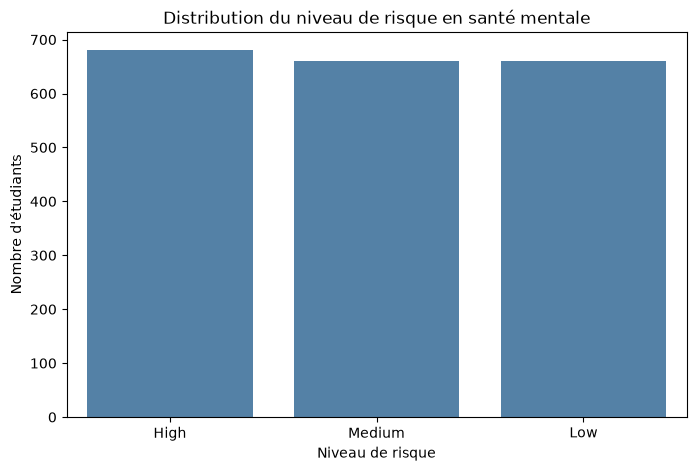

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Mental_Health_Risk",
    color="steelblue",
    legend=False
)

plt.title("Distribution du niveau de risque en santé mentale")
plt.xlabel("Niveau de risque")
plt.ylabel("Nombre d'étudiants")
plt.show()

## Définition des groupes de variables

In [12]:
nominal_cols = ["Gender", "Part_Time_Job", "Previous_Mental_Health_History"]
ordinal_cols = ["Physical_Activity", "Diet_Quality"]
numeric_cols = [
    "Age",
    "Year_of_Study",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate",
]

## Analyse des valeurs aberrantes (Outliers)

In [13]:
outliers = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q2 = df[col].quantile(0.50)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    lower_outliers = df.loc[df[col] < lower, col]
    upper_outliers = df.loc[df[col] > upper, col]

    lower_outliers_str = " | ".join(map(str, lower_outliers.tolist()))
    upper_outliers_str = " | ".join(map(str, upper_outliers.tolist()))

    outliers[col] = {
        "Q1": Q1,
        "Q2": Q2,
        "Q3": Q3,
        "IQR": IQR,
        "Lower": lower,
        "Upper": upper,
        "Lower Outliers": lower_outliers_str,
        "Upper Outliers": upper_outliers_str,
        "Nombre Total Outliers": len(lower_outliers) + len(upper_outliers)
    }

outliers_df = pd.DataFrame(outliers).T

outliers_df.round(2)

,Q1,Q2,Q3,IQR,Lower,Upper,Lower Outliers,Upper Outliers,Nombre Total Outliers
Age,20.0,21.0,23.0,3.0,15.5,27.5,,29 | 28 | 28 | 28,4
Year_of_Study,1.0,2.0,4.0,3.0,-3.5,8.5,,,0
Sleep_Hours,6.0,6.7,7.6,1.6,3.6,10.0,3.6 | 3.3,,2
Study_Hours_Per_Week,16.0,19.8,24.0,8.0,4.0,36.0,3.9 | 3.2 | 3.6 | 2.4 | 2.7,38.3 | 37.5,7
GPA,2.32,2.56,2.79,0.47,1.615,3.495,1.5 | 1.6,3.6 | 3.66 | 3.53 | 3.64 | 3.57 | 3.51 | 3.51,9
Social_Media_Hours,5.225,6.0,6.7,1.475,3.0125,8.9125,2.4 | 2.8 | 2.1 | 3.0 | 2.9 | 2.4,9.0 | 9.4 | 10.0 | 9.0 | 9.1 | 9.0 | 9.4 | 9.0...,20
Screen_Time_Hours,7.4,8.5,9.7,2.3,3.95,13.15,3.4 | 3.8 | 3.8 | 3.3 | 3.8,13.6 | 14.0,7
Financial_Stress,4.5,6.1,7.4,2.9,0.15,11.75,,,0
Family_Support,5.1,6.7,8.0,2.9,0.75,12.35,,,0
Attendance_Rate,80.3,85.1,90.0,9.7,65.75,104.55,61.1 | 62.4 | 62.5 | 62.8 | 62.5 | 63.2 | 65.4...,,12


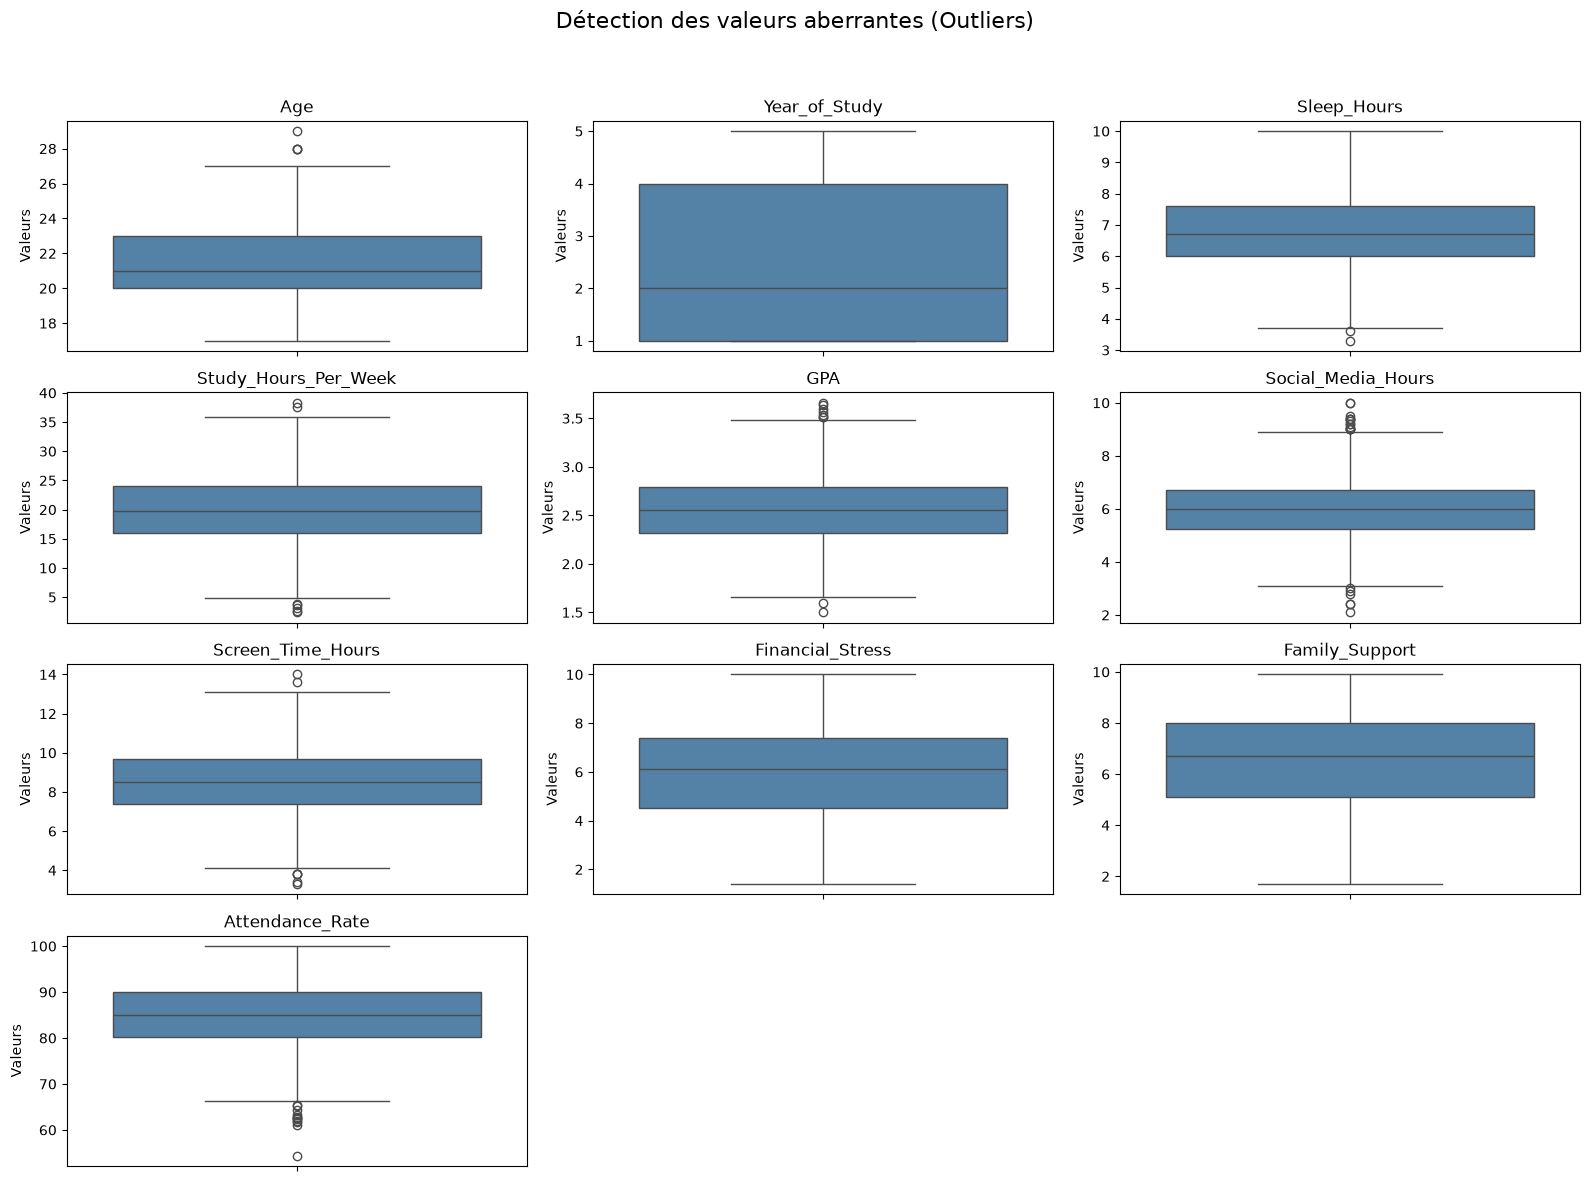

In [14]:
fig, axes = plt.subplots(4, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        data=df,
        y=col,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Valeurs")

for ax in axes[len(numeric_cols):]:
    ax.axis("off")

plt.suptitle("Détection des valeurs aberrantes (Outliers)", fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Analyse univariée des variables numériques

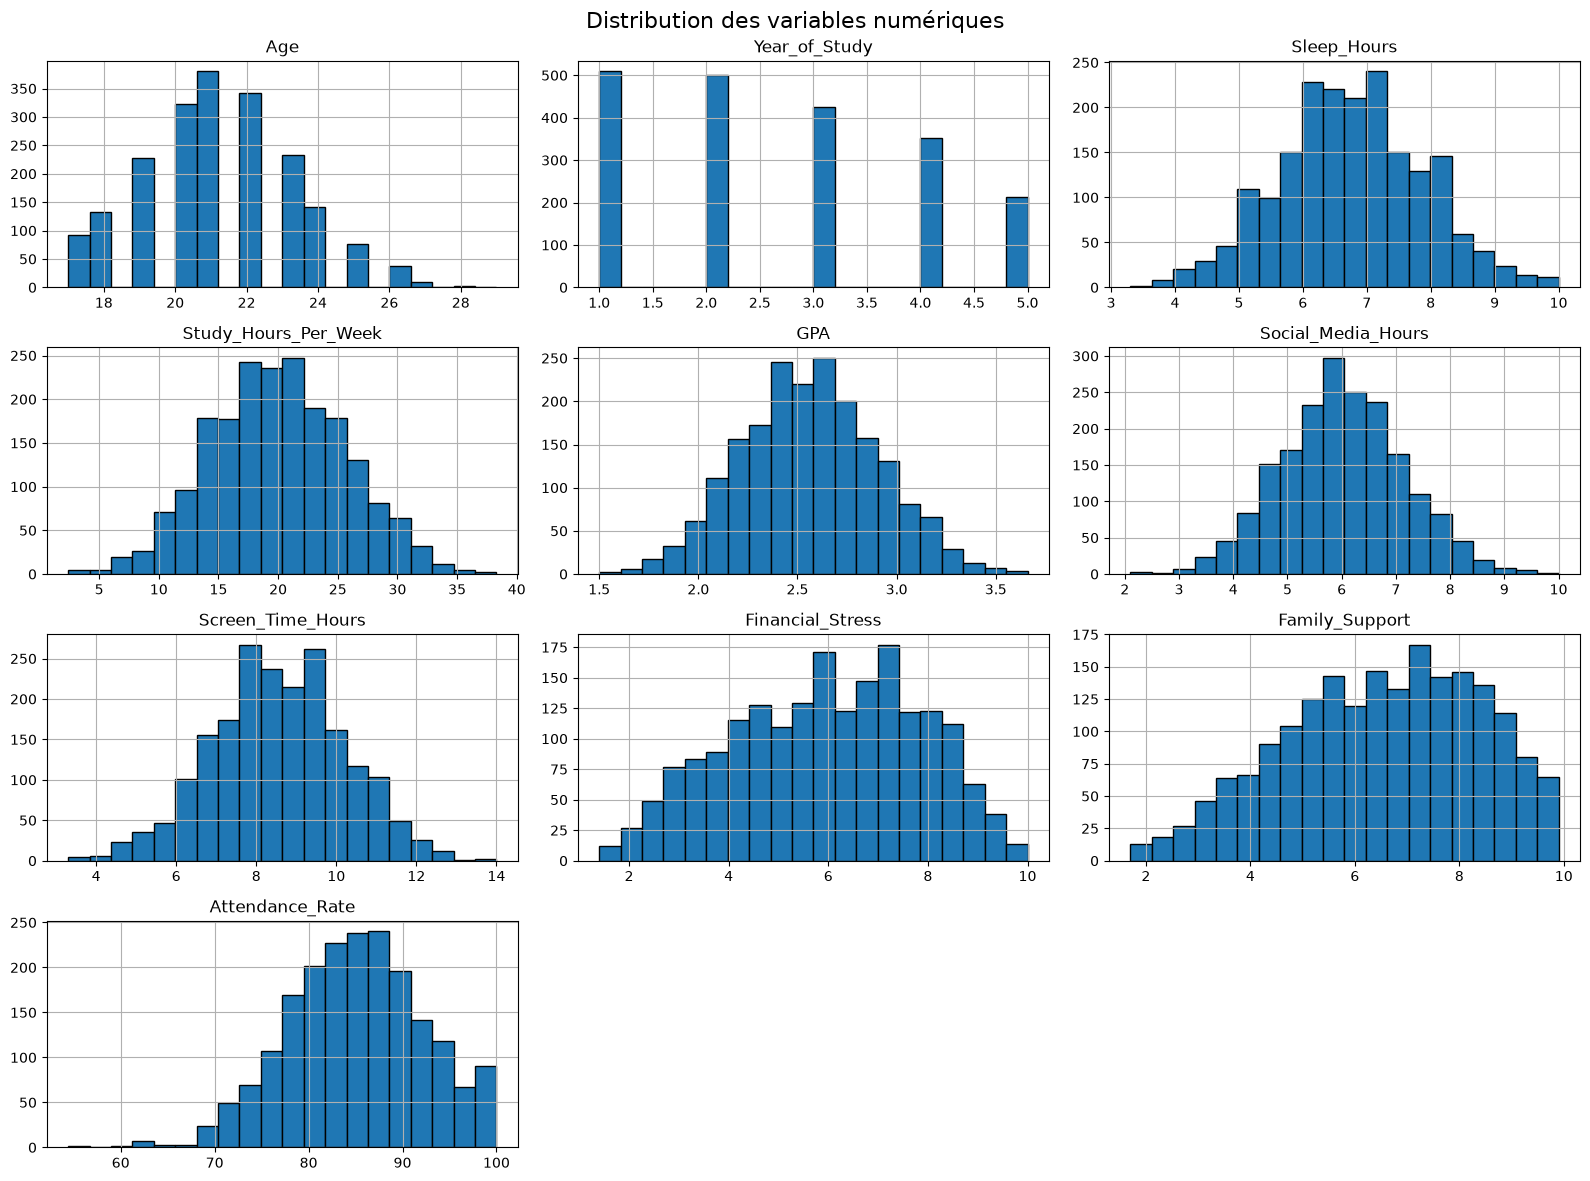

In [15]:
df[numeric_cols].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black",
    layout=(4, 3)
)

plt.suptitle("Distribution des variables numériques", fontsize=16)
plt.tight_layout()
plt.show()

## Analyse univariée des variables catégorielles

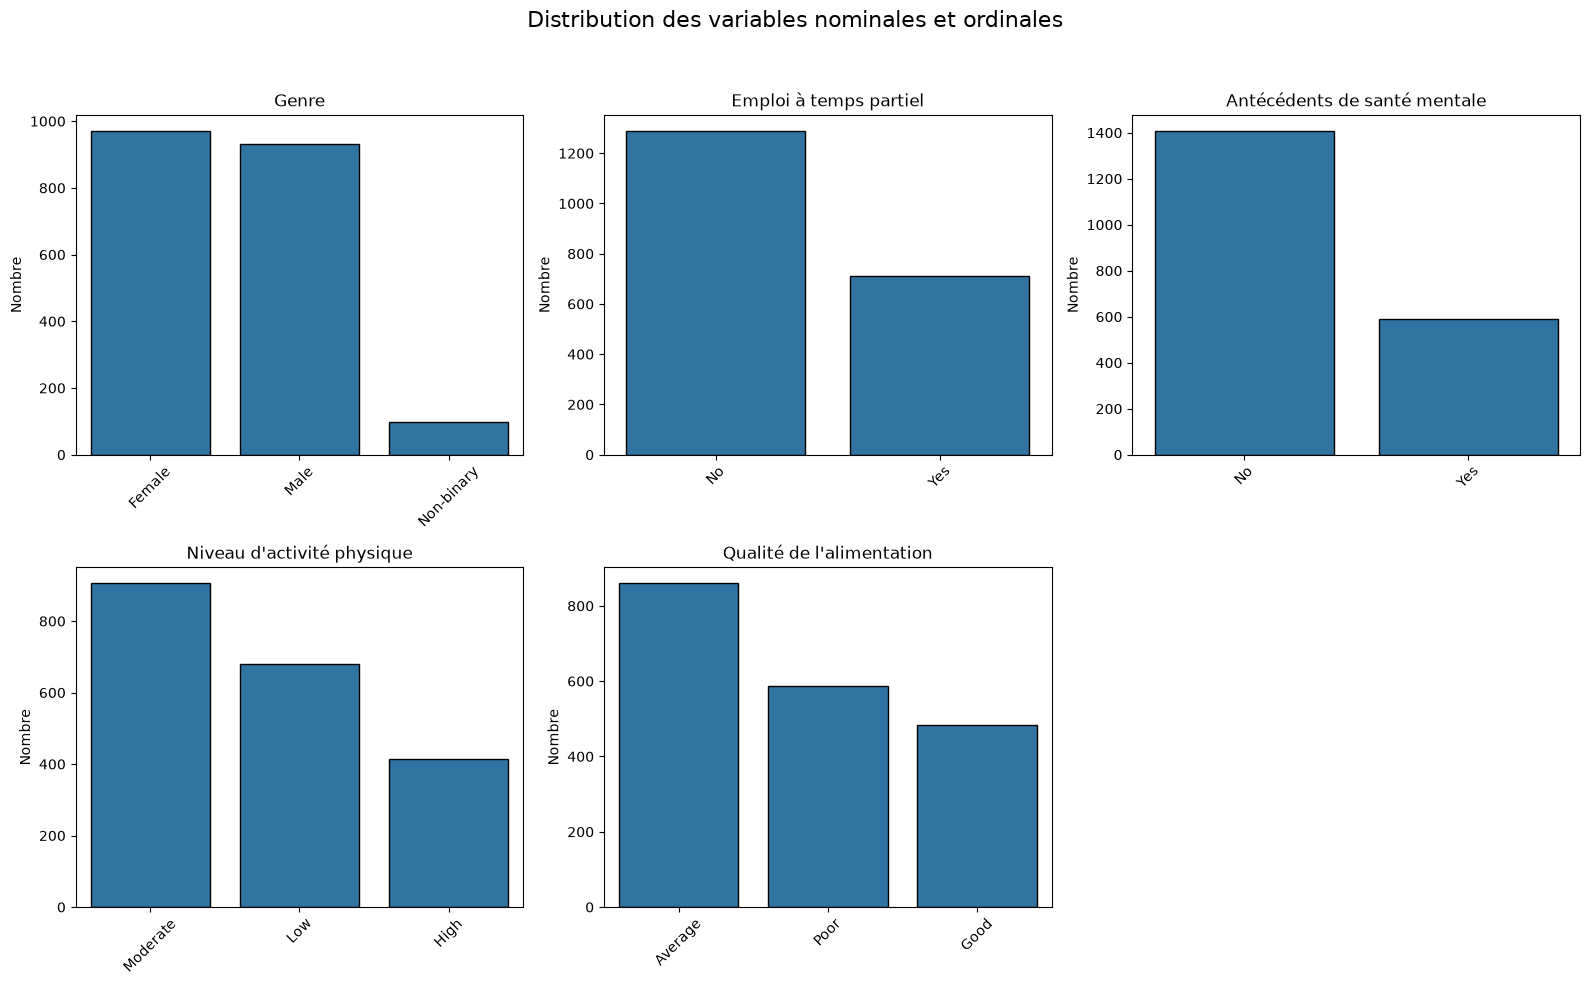

In [16]:
cols_cat = nominal_cols + ordinal_cols

titres = [
    "Genre",
    "Emploi à temps partiel",
    "Antécédents de santé mentale",
    "Niveau d'activité physique",
    "Qualité de l'alimentation"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, col in enumerate(cols_cat):
    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        ax=axes[i],
        edgecolor="black"
    )

    axes[i].set_title(titres[i])
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Nombre")
    axes[i].tick_params(axis="x", rotation=45)

axes[5].axis("off")

plt.suptitle(
    "Distribution des variables nominales et ordinales",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Analyse bivariée : variables numériques et variable cible

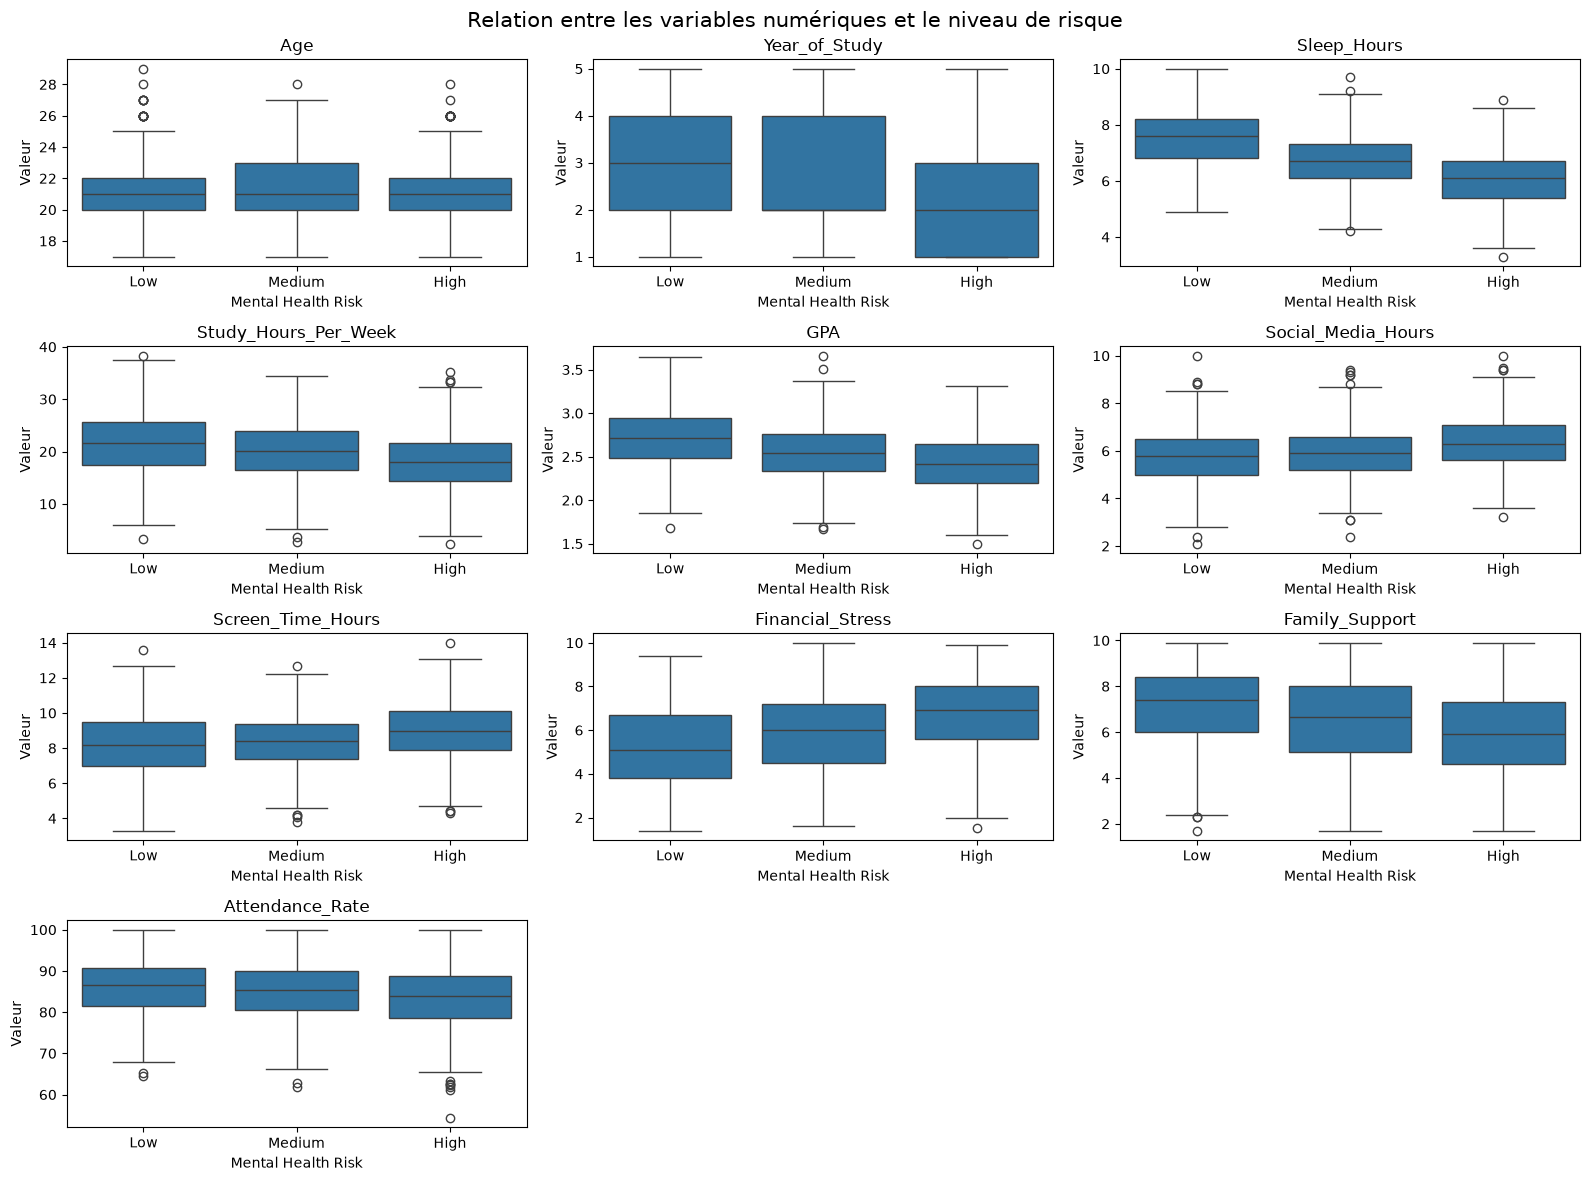

In [17]:
fig, axes = plt.subplots(4, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        data=df,
        x="Mental_Health_Risk",
        y=col,
        ax=axes[i],
        order=["Low", "Medium", "High"]
    )
    axes[i].set_title(col)
    axes[i].set_xlabel("Mental Health Risk")
    axes[i].set_ylabel("Valeur")

for ax in axes[len(numeric_cols):]:
    ax.axis("off")

plt.suptitle("Relation entre les variables numériques et le niveau de risque",
             fontsize=15)
plt.tight_layout()
plt.show()

## Analyse bivariée : variables catégorielles et variable cible

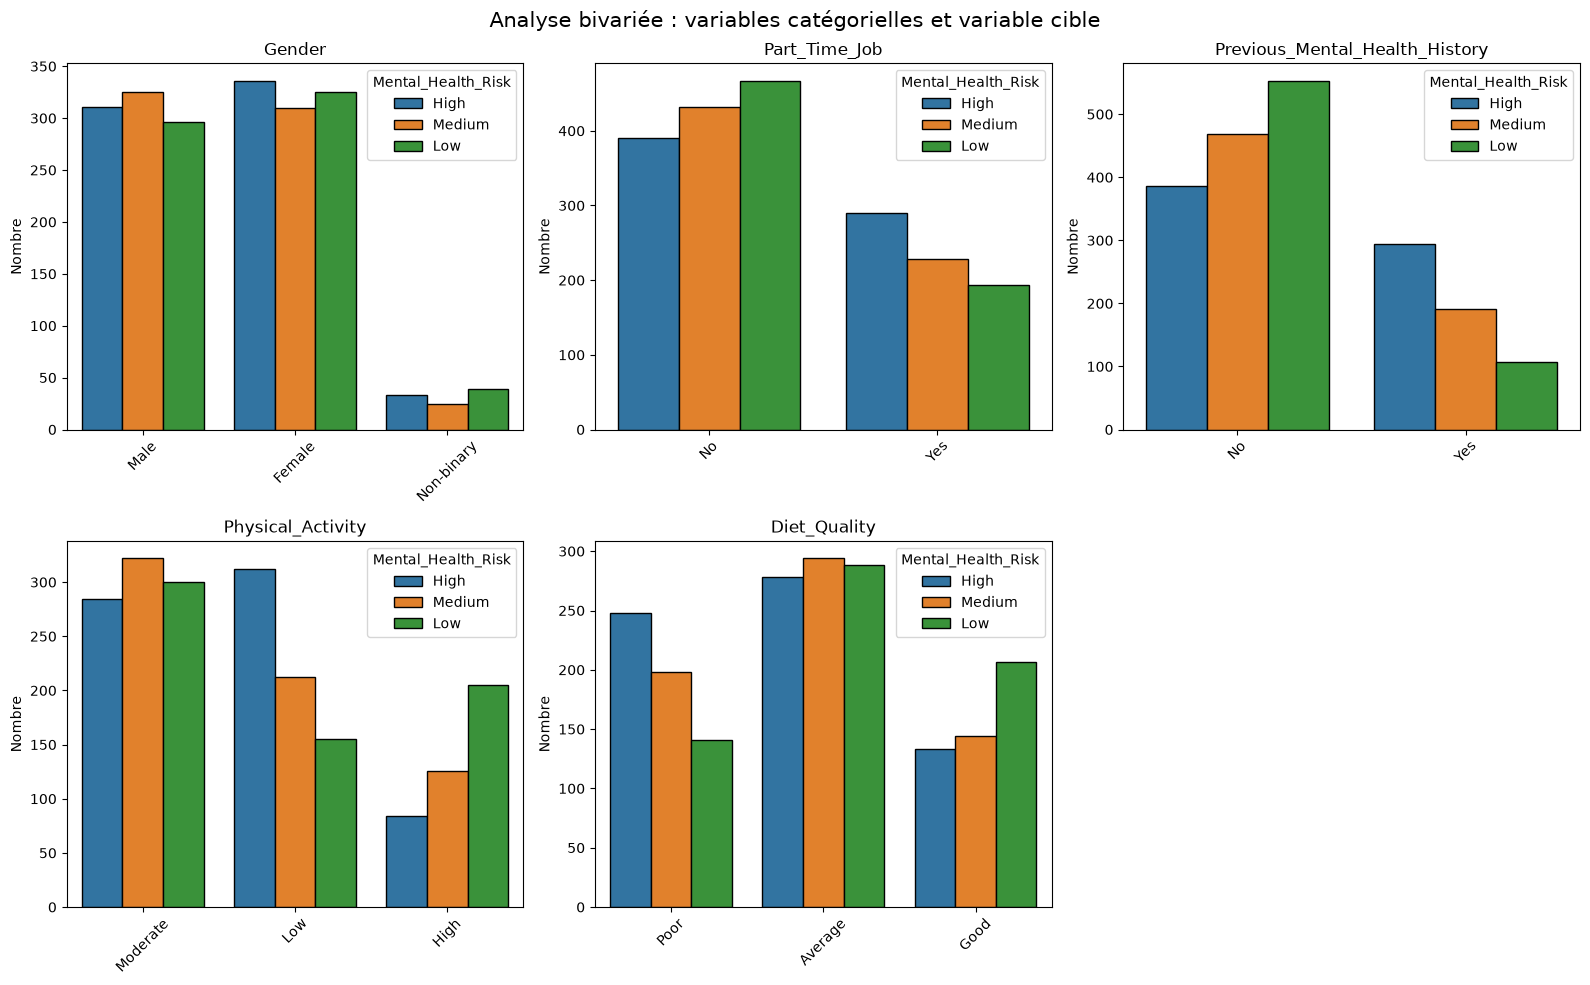

In [18]:
categorical_cols = nominal_cols + ordinal_cols

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=df,
        x=col,
        hue="Mental_Health_Risk",
        ax=axes[i],
        edgecolor="black"
    )
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Nombre")
    axes[i].tick_params(axis="x", rotation=45)

axes[5].axis("off")

plt.suptitle(
    "Analyse bivariée : variables catégorielles et variable cible",
    fontsize=15
)
plt.tight_layout()
plt.show()

## Analyse de corrélation entre les variables numériques

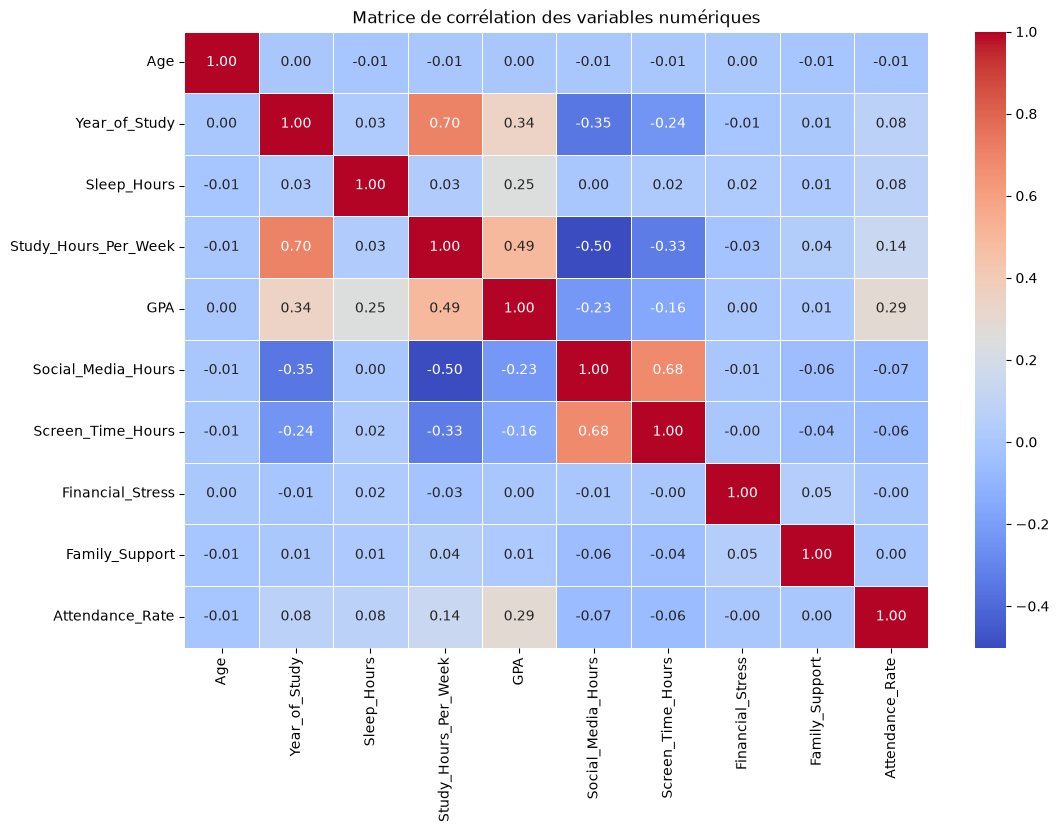

In [19]:
correlation_matrix = df[numeric_cols].corr(method="pearson")

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matrice de corrélation des variables numériques")
plt.show()

# Data Preprocessing

## Correction des incohérences entre Social Media Hours et Screen Time Hours

In [21]:
def swap_values(row):
    if row["Social_Media_Hours"] > row["Screen_Time_Hours"]:
        row["Social_Media_Hours"], row["Screen_Time_Hours"] = (
            row["Screen_Time_Hours"],
            row["Social_Media_Hours"]
        )

    return row

df[["Social_Media_Hours", "Screen_Time_Hours"]] = df[
    ["Social_Media_Hours", "Screen_Time_Hours"]
].apply(swap_values, axis=1)

In [22]:
print("Nombre de cas incohérents :", 
      len(df.loc[df["Social_Media_Hours"] > df["Screen_Time_Hours"]]))

Nombre de cas incohérents : 0


## Ingénierie des Caractéristiques

## Préparation des données

In [23]:
X = df.drop(columns=["Mental_Health_Risk", "Student_ID"])
y = df["Mental_Health_Risk"]

## Préparation des données

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Preprocessing Pipeline

In [25]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[
            ["Low", "Moderate", "High"],
            ["Poor", "Average", "Good"]
        ],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols), 
    ("nom", nominal_pipeline, nominal_cols),
    ("ord", ordinal_pipeline, ordinal_cols)
])

# Modélisation

## Création des Pipelines des modèles

In [26]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=42),
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline(
        [
            ("preprocessor", preprocessor),
            ("feature_selection", SelectKBest(score_func=mutual_info_classif)),
            ("model", model),
        ]
    )

## Définition des hyperparamètres pour GridSearchCV

In [ ]:
param_grids = {
    "Logistic Regression": {
        "feature_selection__k": [10, 15, 20, "all"],
        "model__C": [0.1, 1, 10, 100],
        "model__solver": ["lbfgs", "newton-cg", "sag", "saga"],
        "model__class_weight": [
            None,
            "balanced",
            {"High": 1.0, "Low": 1.0, "Medium": 1.1},
            {"High": 1.0, "Low": 1.0, "Medium": 1.2},
            {"High": 1.0, "Low": 1.0, "Medium": 1.3},
            {"High": 1.0, "Low": 1.0, "Medium": 1.5},
        ],
        "model__max_iter": [1000, 2000],
    },
    "KNN": {
        "feature_selection__k": [10, 15, 20, "all"],
        "model__n_neighbors": [21, 31, 41, 51],
        "model__weights": ["uniform"],
        "model__metric": ["euclidean", "manhattan"],
    },
    "Random Forest": {
        "feature_selection__k": [10, 15, 20, "all"],
        "model__n_estimators": [200, 300],
        "model__max_depth": [3, 5, 7],
        "model__min_samples_split": [10, 20],
        "model__min_samples_leaf": [4, 8],
        "model__max_features": ["sqrt", "log2"],
        "model__class_weight": [None, "balanced"],
    },
}

## Sélection des meilleurs paramètres

In [28]:
best_models = {}
grid_searches = {}

for name, pipeline in pipelines.items():
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=5,
        scoring="f1_macro",
        n_jobs=-1,
        return_train_score=True,
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_
    grid_searches[name] = grid

    print(f"\n{name}")
    print("Best Parameters:", grid.best_params_)
    print("Best CV Score:", round(grid.best_score_, 4))

c:\Users\Youcode\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:782: UserWarning: k=20 is greater than n_features=19. All the features will be returned.
  warnings.warn(



Logistic Regression
Best Parameters: {'feature_selection__k': 20, 'model__C': 1, 'model__class_weight': {'High': 1.0, 'Low': 1.0, 'Medium': 1.1}, 'model__max_iter': 1000, 'model__solver': 'lbfgs'}
Best CV Score: 0.7568

KNN
Best Parameters: {'feature_selection__k': 10, 'model__metric': 'euclidean', 'model__n_neighbors': 31, 'model__weights': 'uniform'}
Best CV Score: 0.6149

Random Forest
Best Parameters: {'feature_selection__k': 15, 'model__class_weight': 'balanced', 'model__max_depth': 7, 'model__max_features': 'log2', 'model__min_samples_leaf': 4, 'model__min_samples_split': 20, 'model__n_estimators': 200}
Best CV Score: 0.6855


## Comparaison des performances

In [29]:
results = []
for name, grid in grid_searches.items():
    idx = grid.best_index_
    train_score = grid.cv_results_["mean_train_score"][idx]
    val_score = grid.cv_results_["mean_test_score"][idx]

    results.append(
        {
            "Model": name,
            "Train F1 Macro": round(train_score, 4),
            "Validation F1 Macro": round(val_score, 4),
            "Gap": round(train_score - val_score, 4),
            "Best Parameters": grid.best_params_,
        }
    )

results_df = pd.DataFrame(results).sort_values(
    by="Validation F1 Macro", ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Train F1 Macro,Validation F1 Macro,Gap,Best Parameters
0,Logistic Regression,0.7689,0.7568,0.0121,"{'feature_selection__k': 20, 'model__C': 1, 'm..."
1,Random Forest,0.8674,0.6855,0.1819,"{'feature_selection__k': 15, 'model__class_wei..."
2,KNN,0.6287,0.6149,0.0138,"{'feature_selection__k': 10, 'model__metric': ..."


## Évaluation des performances

In [30]:
model = best_models["Logistic Regression"]

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro"),
        recall_score(y_test, y_pred, average="macro"),
        f1_score(y_test, y_pred, average="macro"),
        roc_auc_score(
            y_test,
            y_pred_proba,
            multi_class="ovr",
            average="macro"
        )
    ]
})

display(metrics_df.round(4))

,Metric,Score
0,Accuracy,0.7675
1,Precision,0.7708
2,Recall,0.7671
3,F1 Score,0.7686
4,ROC-AUC,0.9139


## Classification Report DataFrame

In [31]:
report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(report_df.round(4))


,precision,recall,f1-score,support
High,0.8271,0.8088,0.8178,136.0000
Low,0.8425,0.8106,0.8263,132.0000
Medium,0.6429,0.6818,0.6618,132.0000
accuracy,0.7675,0.7675,0.7675,0.7675
macro avg,0.7708,0.7671,0.7686,400.0000
weighted avg,0.7714,0.7675,0.7691,400.0000


## Matrice de confusion

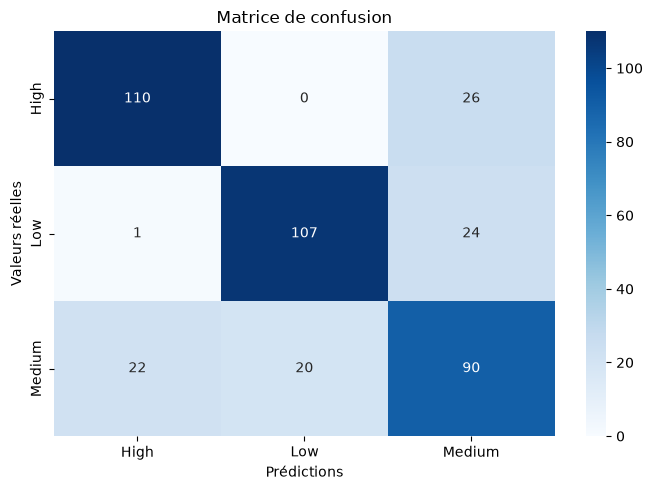

In [32]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=best_models["Logistic Regression"].classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_models["Logistic Regression"].classes_,
    yticklabels=best_models["Logistic Regression"].classes_
)

plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.tight_layout()
plt.show()

## Score ROC-AUC par classe (One-vs-Rest)

In [33]:
roc_auc = roc_auc_score(
    y_test,
    y_pred_proba,
    multi_class="ovr",
    average=None
)

roc_auc_df = pd.DataFrame({
    "Class": best_models["Logistic Regression"].classes_,
    "ROC-AUC": roc_auc
})

display(roc_auc_df.round(4))


,Class,ROC-AUC
0,High,0.9484
1,Low,0.9555
2,Medium,0.8378


## Sauvegarde du modèle entraîné

In [34]:
joblib.dump(
    best_models["Logistic Regression"],
    "../models/best_logistic_regression.pkl"
)

['../models/best_logistic_regression.pkl']